In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [12]:
df = pd.read_csv("noisy_curvefit_data.csv")

print("Shape:", df.shape)
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print("Column names:", list(df.columns))
print("First five rows:")
print(df.head())
print("Last five rows:")
print(df.tail())

Shape: (100, 6)
Rows: 100 | Columns: 6
Column names: ['x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']
First five rows:
          x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0 -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1 -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2 -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3 -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4 -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113
Last five rows:
           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850


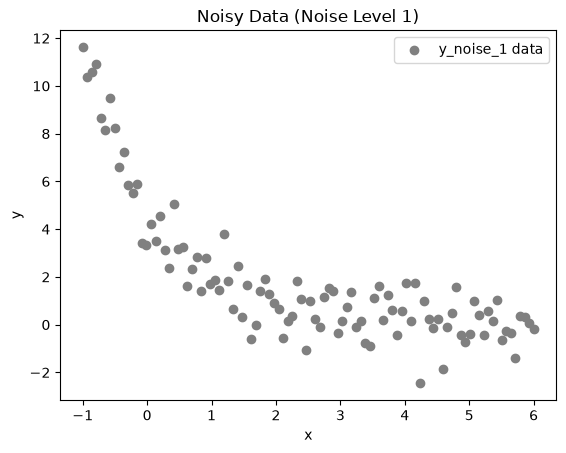

In [13]:
x = df["x"]
y_noise_1 = df["y_noise_1"]

plt.scatter(x, y_noise_1, color="gray", label="y_noise_1 data")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Noisy Data (Noise Level 1)")
plt.legend()
plt.show()

2.2 Fit the data

In [14]:
def model(x, A, k):
    # y = A * e^(-k * x)
    return A * np.exp(-k * x)

p0 = [1, 1]
popt, pcov = curve_fit(model, x, y_noise_1, p0=p0)
A_fit, k_fit = popt

print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2 / dof
print(f"Chi-squared reduced: {chi2_reduced:.2f}")

Fit: y = 4.71 * e^(-0.92 * x)
Chi-squared reduced: 0.79


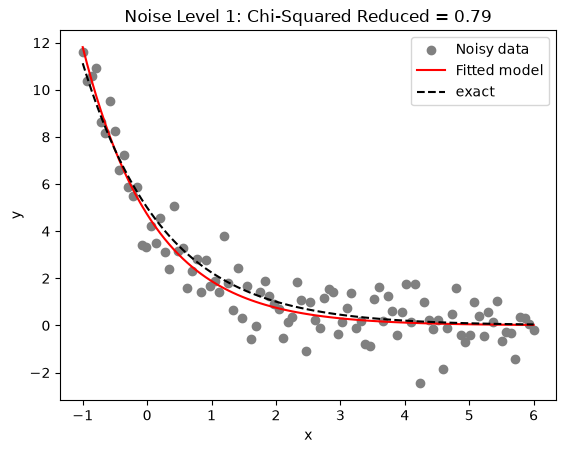

In [15]:
plt.scatter(x, y_noise_1, color="gray", label="Noisy data")
plt.plot(x, model(x, A_fit, k_fit), color="red", label="Fitted model")
plt.plot(x, model(x, 5, 0.8), color="black", linestyle="--", label="exact")
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Noise Level 1: Chi-Squared Reduced = {chi2_reduced:.2f}")
plt.legend()
plt.show()

2.3 Compare different noise leves

In [18]:
def fit_model(x, y):
    # fits the model and returns the best-fit parameters and the reduced chi-squared
    popt, pcov = curve_fit(model, x, y, p0=[1, 1])
    residuals = y - model(x, *popt)
    chi2_reduced = np.sum(residuals**2) / (len(x) - len(popt))
    return popt, chi2_reduced

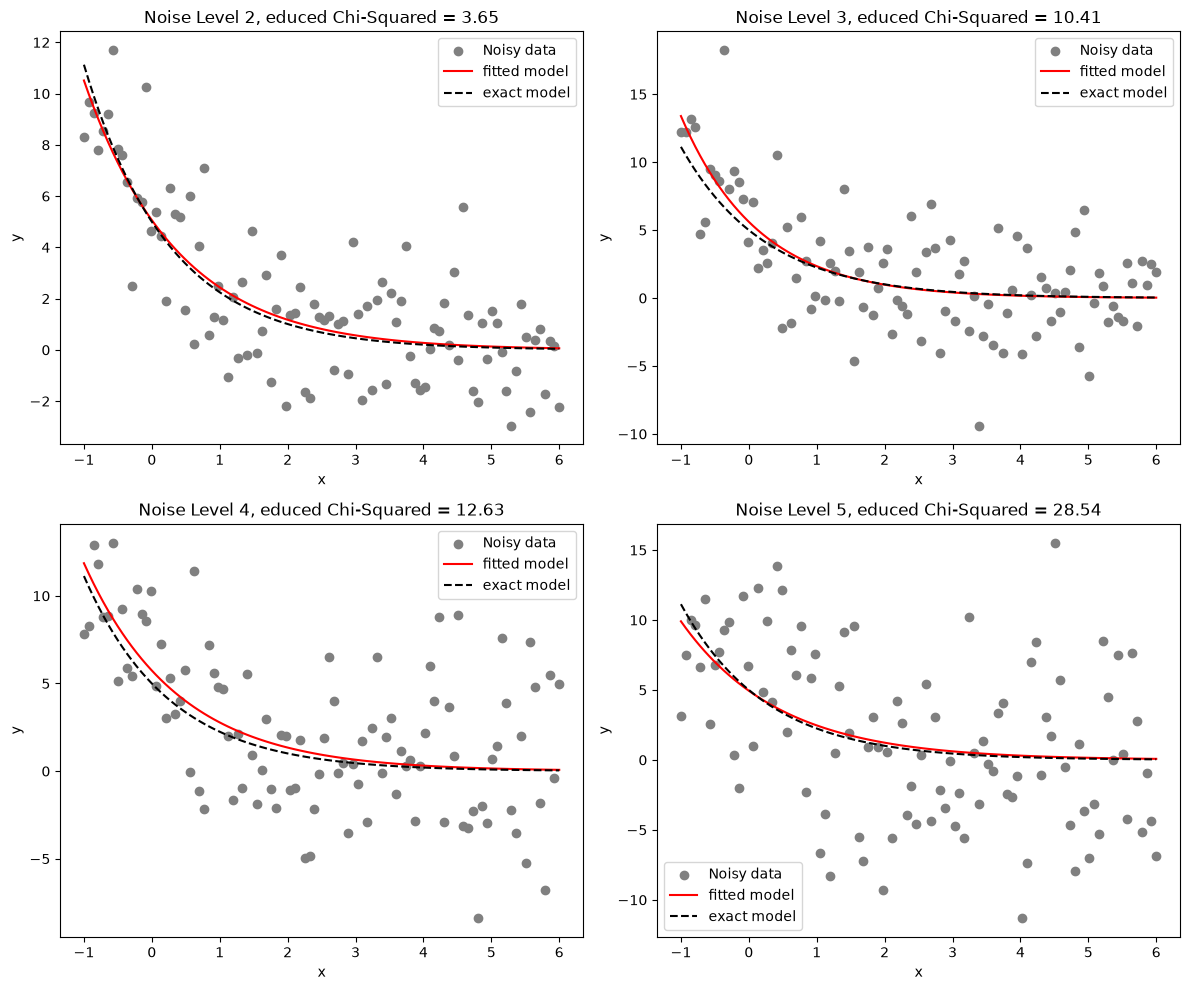

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

noise_levels = [2, 3, 4, 5]
for ax, level in zip(axes, noise_levels):
    y = df[f"y_noise_{level}"]
    popt, chi2_red = fit_model(x, y)

    ax.scatter(x, y, color="gray", label="Noisy data")
    ax.plot(x, model(x, *popt), color="red", label="fitted model")
    ax.plot(x, model(x, 5, 0.8), color="black", linestyle="--", label="exact model")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"Noise Level {level}, educed Chi-Squared = {chi2_red:.2f}")
    ax.legend()

plt.tight_layout()
plt.show()

What happens to the red and black dotted lines as the noise level increases?

The black dotted line is the actual model, so it never changes. The red fitted line stays close to it at low noise, but at higher noise it starts to stray away from it. The points scatter more around the true curve so the curve gets moved around more by the random points and is a worse estimate of the true A and k.

What happens to the reduced chi-squared as the noise level increases?

It gets bigger (0.79, 3.65, 10.41, 12.63, 28.54 for noise levels 1 to 5). The reduced chi-squared is the average of all of the points' distance from the fit, squared, so more noise means the points sit farther from the curve and the value grows, roughly like the noise squared. Noise level 1 gives a value close to 1, which is what a good fit should be around.

2.4 save your results

In [20]:
levels = [1, 2, 3, 4, 5]
A_values = []
k_values = []
chi2_values = []

for level in levels:
    popt, chi2_red = fit_model(x, df[f"y_noise_{level}"])
    A_values.append(popt[0])
    k_values.append(popt[1])
    chi2_values.append(chi2_red)

results = pd.DataFrame({
    "Noise Level": levels,
    "A_fit": A_values,
    "k_fit": k_values,
    "Reduced Chi-Squared": chi2_values
})
print(results)
print("Shape:", results.shape)

results.to_csv("noisy_parameters.csv", index=False)

   Noise Level     A_fit     k_fit  Reduced Chi-Squared
0            1  4.714814  0.918308             0.790673
1            2  5.063889  0.730396             3.649382
2            3  5.609396  0.870372            10.410207
3            4  5.738727  0.725965            12.626832
4            5  4.943458  0.695012            28.538124
Shape: (5, 4)
